In [1]:
%load_ext autoreload
%autoreload 2
import emcee
import numpy as np
from matplotlib import pyplot as plt
from astropy import units as u
from astropy import constants as const
from sklearn.metrics import r2_score
import pickle
from multiprocessing import Pool

from functions.load_data_and_var import load_data_and_var, generate_nfws_from_combined_dataset_werr
from functions.plotting import savefig, paper_plot
from functions.statistics_functions import chi_squared
from cluster_class.cluster_functions import T500_from_L500, E_tot

In [2]:
with open('data/equilibrium_clusters.pkl', 'rb') as file:
    # Load the data into nfws_subset variable
    nfws_subset = pickle.load(file)

In [3]:
len(nfws_subset)

49

In [4]:
mchis = np.logspace(-4, -1, num=20)
mchis

array([0.0001    , 0.00014384, 0.00020691, 0.00029764, 0.00042813,
       0.00061585, 0.00088587, 0.00127427, 0.00183298, 0.00263665,
       0.00379269, 0.00545559, 0.0078476 , 0.01128838, 0.01623777,
       0.02335721, 0.03359818, 0.0483293 , 0.06951928, 0.1       ])

In [5]:
cls = nfws_subset[0]

In [6]:
G_conv = (const.G/const.c**2).to(u.Mpc/u.Msun)

In [8]:
cls_energy_rate = E_tot(cls)/(u.Gyr.to(u.s)*10) # in ergs/s
cls_energy_rate

2.429364921419688e+46

In [9]:
cls.R500

In [10]:
dm_cooling_no_s0=[]
for m in mchis:
    dm_cooling_no_s0.append(cls.integrated_dm_cooling_rate(0.001*cls.R500,
                                                           cls.R500,
                                                           1,
                                                           m,))

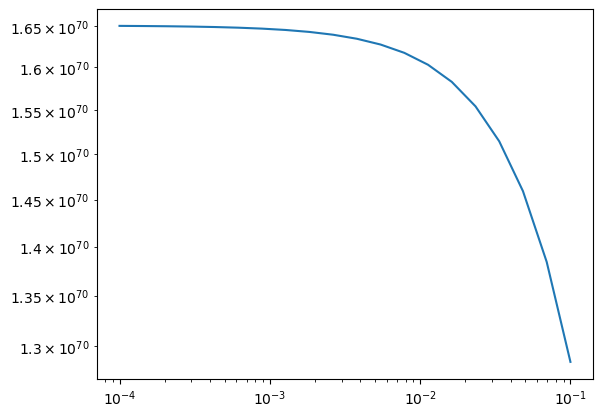

In [11]:
plt.loglog(mchis, dm_cooling_no_s0)

In [12]:
sigma0s = np.divide(cls_energy_rate, dm_cooling_no_s0)

Text(0.5, 1.0, 'total energy constraint from 1 cluster')

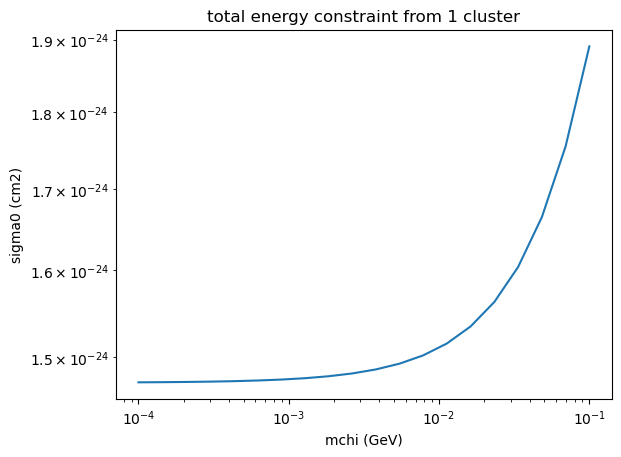

In [13]:
plt.loglog(mchis, sigma0s)
plt.xlabel('mchi (GeV)')
plt.ylabel('sigma0 (cm2)')
plt.title('total energy constraint from 1 cluster')

In [14]:
sigma0s_nested_list = []
for n in nfws_subset: 
    cls_energy_rate = E_tot(n)/(u.Gyr.to(u.s)*10) # in ergs/s
    dm_cooling_no_s0=[]
    for m in mchis:
        dm_cooling_no_s0.append(n.integrated_dm_cooling_rate(0.001*n.R500,
                                                               n.R500,
                                                               1,
                                                               m,)) # in erg/s/cm2
    sigma0s = np.divide(cls_energy_rate, dm_cooling_no_s0)
    sigma0s_nested_list.append(sigma0s)
    
# sigma0s_nested_list is now a list of sigma0s lists
# where the sigma0s lists are functions of mchi 
# and each list corresponds to the cluster of the same index in nfws_subset

In [15]:
np.shape(sigma0s_nested_list)

(49, 20)

In [16]:
np.shape(sigma0s_nested_list[0])

(20,)

Text(0.5, 1.0, 'total energy constraint from 49 equilibrium clusters')

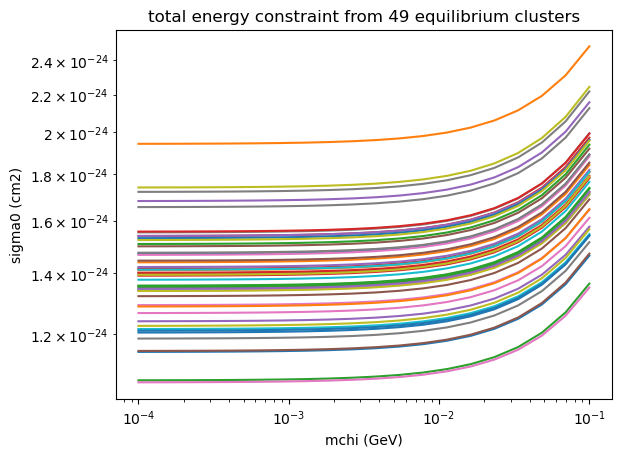

In [17]:
for sigma0s in sigma0s_nested_list:
    plt.loglog(mchis, sigma0s)
    
plt.xlabel('mchi (GeV)')
plt.ylabel('sigma0 (cm2)')
plt.title('total energy constraint from 49 equilibrium clusters')

In [18]:
avg_sigma0s_unweighted=np.average(sigma0s_nested_list, axis=0)
np.shape(avg_sigma0s_unweighted)

(20,)

Text(0.5, 1.0, 'avg total energy constraint (unweighted)')

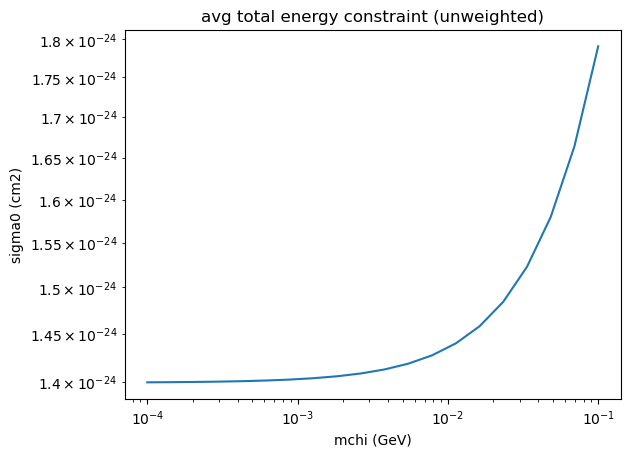

In [19]:
plt.loglog(mchis, avg_sigma0s_unweighted)
plt.xlabel('mchi (GeV)')
plt.ylabel('sigma0 (cm2)')
plt.title('avg total energy constraint (unweighted)')

In [20]:
sigma0s_95_unweighted=np.percentile(sigma0s_nested_list,95, axis=0)
np.shape(sigma0s_95_unweighted)

(20,)

Text(0.5, 1.0, 'total energy constraint (95% curve, no error bars)')

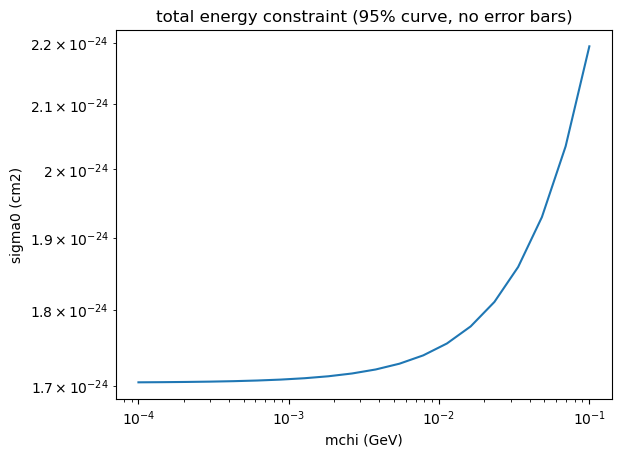

In [21]:
plt.loglog(mchis, sigma0s_95_unweighted)
plt.xlabel('mchi (GeV)')
plt.ylabel('sigma0 (cm2)')
plt.title('total energy constraint (95% curve, no error bars)')

In [22]:
sigma0s_95_unweighted[0].value

1.7044406385747438e-24

In [23]:
sigma0s_95_unweighted[-1].value

2.1937765146140976e-24